# Семинар 12 [17-25-2]. От Python к распределениям SciPy

Цель: самим открыть документацию [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html),
создать распределение, получить выборку и теоретические величины, сравнить их и нарисовать.

Задания идут лесенкой:

1. **Ступень 1 — по образцу.** Есть готовый пример, вы подставляете свои параметры.
2. **Ступень 2 — сами.** Выбираете и комбинируете то, что узнали; одно распределение находите в документации сами.
3. **Ступень 3 — задание с прошлого семинара.** Дописываете код с опорой на документацию.

**Перед каждой ячейкой с кодом запишите предсказание:** что она выведет или нарисует.
Потом запустите и сравните. Не совпало — это самое интересное место, разберитесь почему.

**Запуск.** В Colab загрузите скачанный `.ipynb` через «Файл → Загрузить блокнот».
Выполняйте ячейки по порядку сверху вниз (`Shift+Enter`). Если что-то сломалось —
«Среда выполнения → Перезапустить сеанс» и снова сверху вниз.

## Подготовка

Выполните обе ячейки: первая подключает библиотеки, вторая создаёт готовую функцию `plot_dist(sample, dist)` — она рисует выборку и теоретический закон на одном графике.

In [142]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [143]:
# @title Готовая функция plot_dist (выполните ячейку, разбирать код не нужно)
def plot_dist(sample, dist, title=None):
    """Рисует выборку и теоретический закон на одном графике.

    sample — массив наблюдений (например, результат dist.rvs(...)),
    dist   — «замороженное» распределение, например stats.binom(n=10, p=0.3).
    """
    if not hasattr(dist, "dist"):
        raise TypeError("plot_dist ждёт распределение с параметрами, "
                        "например stats.binom(n=10, p=0.3), а не stats.binom.")
    sample = np.asarray(sample, dtype=float)
    if sample.ndim != 1 or sample.size == 0:
        raise ValueError("Первый аргумент — непустой одномерный массив наблюдений.")

    fig, ax = plt.subplots(figsize=(8, 4))
    lo = min(sample.min(), dist.ppf(0.001))
    hi = max(sample.max(), dist.ppf(0.999))
    if isinstance(dist.dist, stats.rv_discrete):
        values, counts = np.unique(sample, return_counts=True)
        ax.bar(values, counts / sample.size, width=0.8, color="#1F6BFF",
               alpha=0.35, label="частоты в выборке")
        ks = np.arange(np.floor(lo), np.ceil(hi) + 1)
        ax.vlines(ks, 0, dist.pmf(ks), color="#111827", lw=1.5)
        ax.plot(ks, dist.pmf(ks), "o", color="#111827", ms=5, label="pmf (теория)")
        ax.set_ylabel("вероятность / частота")
    else:
        ax.hist(sample, bins=50, density=True, color="#1F6BFF", alpha=0.35,
                label="гистограмма выборки")
        xs = np.linspace(lo, hi, 400)
        ax.plot(xs, dist.pdf(xs), color="#111827", lw=2, label="pdf (теория)")
        ax.set_ylabel("плотность")
    ax.set_xlabel("значение")
    ax.set_title(title or f"{dist.dist.name}: {sample.size} наблюдений")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

## Ступень 1. По образцу

### Образец

Ниже всё уже написано. Прочитайте каждую строку и запустите. Предсказание — для каждой ячейки.

**Предсказание** (до запуска, словами): X становится обьетом класса и с помощью X можно использовать методы класса например: .rvs 
sample_x нам выведет массив успешных испытаний из 10 испытаний, а именно 10 опытов 

In [144]:
X = stats.binom(n=10, p=0.3)           # биномиальный закон: 10 опытов, вероятность успеха 0.3
sample_x = X.rvs(size=100, random_state=1)
sample_x[:10]

array([3, 4, 0, 2, 1, 1, 2, 2, 3, 3])

**Предсказание** (до запуска, словами): на графике мы увидим распределение частоты значений, где наибольшее количество выпадений именно 3, так как у нас 10 опытов и вероятность 0.3 

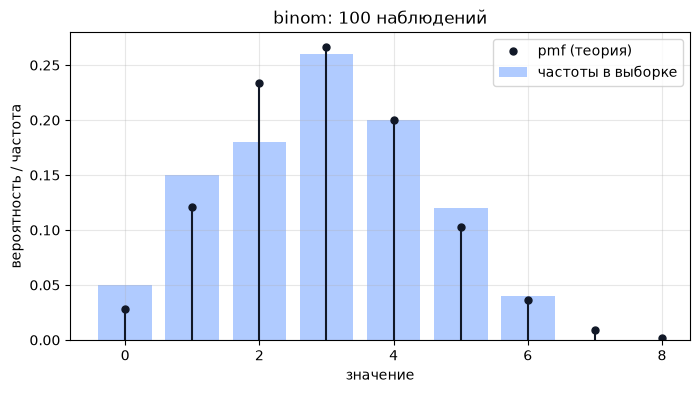

In [145]:
plot_dist(sample_x, X)

**Предсказание** (до запуска, словами): тут мы используем методы .mean() - для мат ожидания, .var() - для дисперсии

In [146]:
print(f"E(X):   теория {X.mean():.3f}, выборка {sample_x.mean():.3f}")
print(f"Var(X): теория {X.var():.3f}, выборка {sample_x.var():.3f}")

E(X):   теория 3.000, выборка 2.930
Var(X): теория 2.100, выборка 2.265


### 1.1. Биномиальный закон

Создайте биномиальный закон `B` с $n=20$ и $p=0{,}25$. Получите выборку `sample_b` из 10 000 наблюдений
с `random_state=2`, нарисуйте её через `plot_dist` и выведите $E$ и $\mathrm{Var}$: теоретические и выборочные.
Замените `...` по образцу.

**Предсказание** (до запуска, словами): ну опять же, B делаем обьектом класса и к нему применяем метод .rvs.
по данным сделаем предсказание: если опытов 20, а вероятность 0.25, то больше всего успешных исходов из 10 испытаний будет 5.
чем больше у нас наблюдей тем ближе мы будем к мат ожиданию 

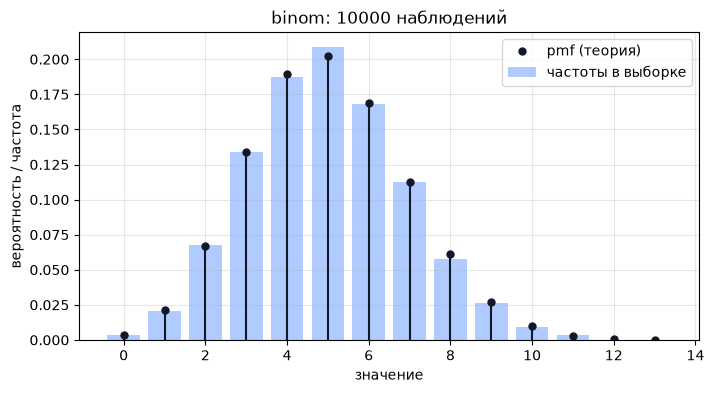

E(B):   теория 5.000, выборка 4.986
Var(B): теория 3.750, выборка 3.684


In [147]:
B = stats.binom(n=20, p=0.25)
sample_b = B.rvs(size=10000, random_state=1)
plot_dist(sample_b, B)
print(f"E(B):   теория {B.mean():.3f}, выборка {sample_b.mean():.3f}")
print(f"Var(B): теория {B.var():.3f}, выборка {sample_b.var():.3f}")

### 1.2. Нормальный закон

Создайте нормальный закон `N` с $E(N)=50$ и стандартным отклонением $\sigma=5$.
Остальное — как в 1.1, `random_state=3`. У нормального закона в SciPy параметры называются `loc` и `scale`.

**Предсказание** (до запуска, словами): тут уже нормальное распределение. Опять же делаем N обьектом класса и применяем метод .rvs.
Примерно ожидаем, что все наблюдения будут примерно описывать волну (колокол) и при увеличении наблюдений точность будет расти, то есть будем приближаться к мат ожиданию 

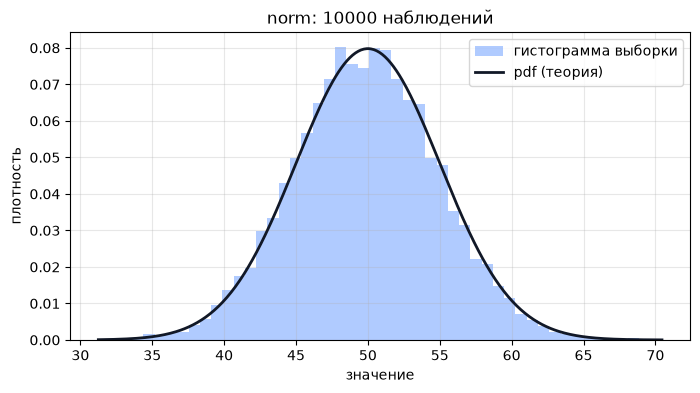

E(N):   теория 50.000, выборка 49.862
Var(N): теория 25.000, выборка 24.795


In [148]:
N = stats.norm(50, 5)
sample_n = N.rvs(size=10000, random_state=3)
plot_dist(sample_n, N)
print(f"E(N):   теория {N.mean():.3f}, выборка {sample_n.mean():.3f}")
print(f"Var(N): теория {N.var():.3f}, выборка {sample_n.var():.3f}")

### 1.3. Проверьте себя

Почему выборочные $E$ и $\mathrm{Var}$ близки к теоретическим, но не равны им?
Что изменится, если взять `random_state=4`? А если `size=100`?

**Ответ:** берем E(N) = 50, но фактически мы говорим: взять случайную величину, где мат ожидание 50, а Var(N) дисперсия считается, как квадрат стандартного отклонения, Var(N) = sigma^2. При увеличении наблюдений мы будем приближаться к мат ожиданию, но при не достаточных наблюдениях у нас выборка не будет равняться теории. Если взять random_state=4, то мы получим другие результаты, отличные от random_state=3, но если мы берем постоянно один и тот же random_state, то всегда будем получать одни и те же значения. Вообще random_state задает какой то определенный seed, который как раз и задает псевдорандом

## Ступень 2. Сами выбираете и комбинируете

### 2.1. Несколько законов в словаре

Соберите четыре закона:

| Имя | Закон | Параметры |
|---|---|---|
| `"binom"` | биномиальный | $n=20$, $p=0{,}25$ |
| `"norm"` | нормальный | $E=50$, $\sigma=5$ |
| `"poisson"` | Пуассона | $\lambda=3$ |
| `"expon"` | показательный | интенсивность $\lambda=0{,}5$ |

Законы Пуассона и показательный найдите в документации [scipy.stats](https://docs.scipy.org/doc/scipy/reference/stats.html) сами:
как называются, какие у них параметры, как они связаны с $\lambda$. Проверьте себя: должно выйти $E=3$ и $E=2$.

**Структуры данных.**
- `params` — словарь: имя закона → словарь его параметров, например `"binom": {"n": 20, "p": 0.25}`.
- `laws` — словарь: имя закона → замороженное распределение, созданное из `params`.
- `samples` — словарь: имя закона → выборка из 10 000 наблюдений (`random_state=5`).

Для каждого закона выведите имя, теоретические и выборочные $E$ и $\mathrm{Var}$ и нарисуйте `plot_dist`.

**Предсказание** (до запуска, словами): так у нас есть, словарь params и мы в нем записываем методы и нужные значения для методов. Словарь, для удобства, чтобы вместе доставать методы и значения

In [168]:
params = {
    "binom": {"n": 20, "p": 0.25},
    "norm": {"loc": 50, "scale": 5},
    "poisson": {"mu": 3},
    "expon": {"scale": 0.5}
}

### 2.2. Вероятность события: доля в выборке и теория

Для каждого события оцените вероятность **долей в выборке** (маской) и посчитайте её **методом закона** (`cdf` или `sf`).
Выведите оба числа рядом.

1. биномиальный: $P(X\ge 8)$;
2. нормальный: $P(45<X<55)$;
3. Пуассона: $P(X\le 1)$;
4. показательный: $P(X>4)$.

Перед кодом запишите, какой метод и с каким аргументом нужен в каждом случае. Осторожно с границей у дискретных законов.

**Методы:** для расчета каждой вероятности из импортированной библиотеки scipy берем .binom (для первого распрелеления: биноминального) вызываем метод .sf(), так как нам нужно посчитать больше или равно $P(X\ge 8)$ и нужно учесть, что .sf() берет строго больше, а не больше или равно, поэтому в параметрах мы укажем k = 7. Теперь возьмем пример, где используем .cdf(). Опять же scipy.poisson.cdf() для $P(X\le 1) и в параметрах .cdf() мы запишем 1, так как тут именно меньше или равно. По такой схеме пишем для всех распределний вероятности.

то есть если в ручную расписывать должно получится вот так:

1. binom: P(X>=8): stats.binom.sf(7, 20, 0.25)
2. norm: P(45<X<55): stats.norm.sf(45, 50, 5) - stats.norm.cdf(54, 50, 5)
3. poisson: P(X<=1): stats.poisson.cdf(1, 3)
4. expon: P(X>4): stats.expon.sf(4, 0.5)

In [170]:
for name, law_params in params.items():
    law = getattr(stats, name)(**law_params)
    if name == 'binom':
        print(f'binom: P(X>=8): {law.sf(7):.3f}')
    elif name == 'norm':
        print(f'norm: P(45<X<55): {(law.sf(45)-law.cdf(54)):.3f}')
    elif name == 'poisson':
        print(f'poisson: P(X<=1): {law.cdf(1):.3f}')
    elif name == 'expon':
        print(f'expon: P(X>4): {law.sf(4):.3f}')

binom: P(X>=8): 0.102
norm: P(45<X<55): 0.053
poisson: P(X<=1): 0.199
expon: P(X>4): 0.000


### 2.3. Меняем параметр

Нарисуйте рядом (две ячейки или одну за другой): биномиальный закон с $n=20$ при $p=0{,}25$ и при $p=0{,}5$;
нормальный с $E=50$ при $\sigma=5$ и при $\sigma=10$. Для каждого — выборка и `plot_dist`.
Сначала предскажите, что сдвинется, а что станет шире.

**Предсказание** (до запуска, словами): для биномиального: при изменении p мы будем двигаться вправо (влево), в данном случае, мы сдвинемся вправо на 5, то есть основное кол-во успехов при 20 опытах будет 10, а также увеличится размазаность графика, то есть пик графика ниже и края растянуться в стороны. Для нормального: при изменении sigma, мы не двигаем центр, но наша волна(колокол) становится шире и пик этой волны становится ниже, то есть мы, грубо говоря, прижимаем волну вниз

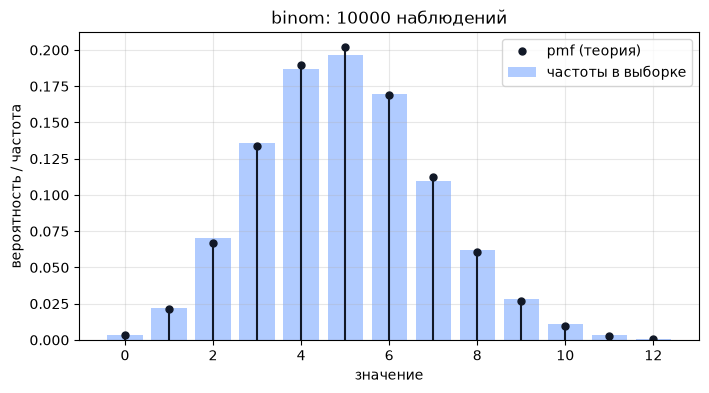

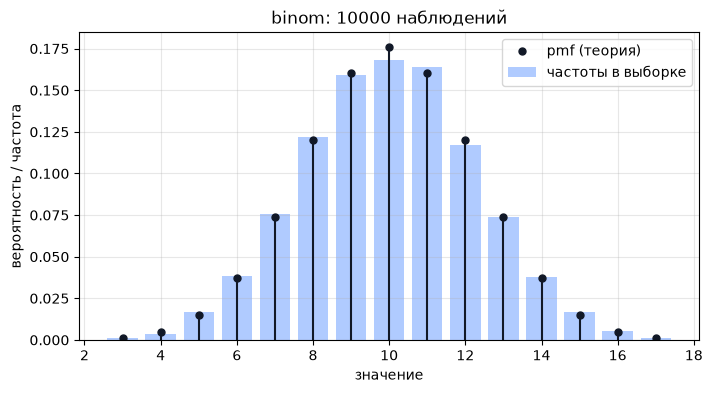

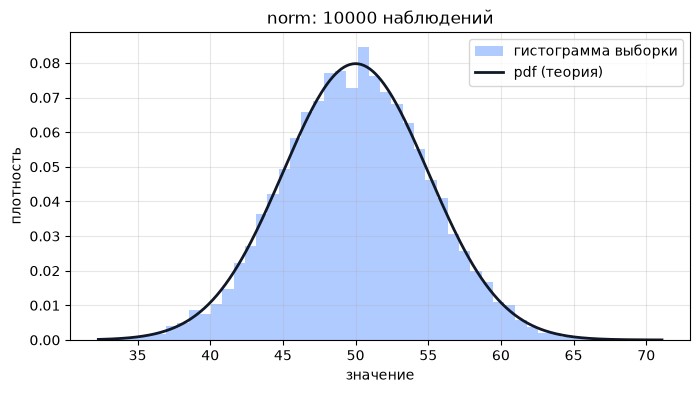

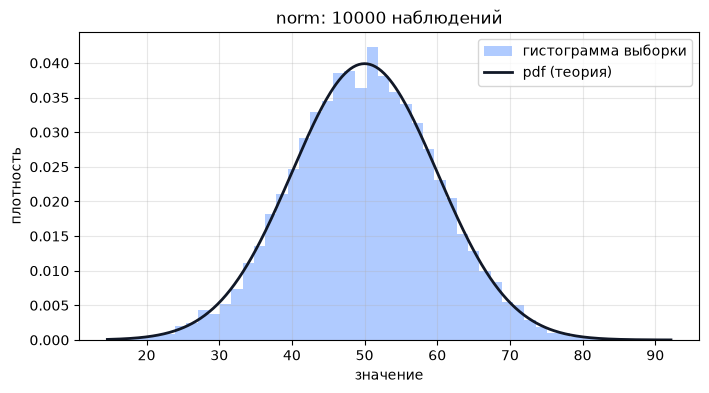

In [171]:
# биномиальное 
B = stats.binom(20, 0.25)
sample_b = B.rvs(size=10000, random_state=4)
plot_dist(sample_b, B)
B = stats.binom(20, 0.5)
sample_b = B.rvs(size=10000, random_state=4)
plot_dist(sample_b, B)

# нормальное 
N = stats.norm(50, 5)
sample_n = N.rvs(size=10000, random_state=4)
plot_dist(sample_n, N)
N = stats.norm(50, 10)
sample_n = N.rvs(size=10000, random_state=4)
plot_dist(sample_n, N)

Как изменились графики и почему? Свяжите с формулами $E$ и $\mathrm{Var}$.

**Ответ:** все как и ожидалось изменилось. В биномиальном у нас сдвинулась волна вправо до 10 и прижалась вниз (уменьшается пик и шире график), потому что по формулам `P(X = k) = C(n, k) * p^k * (1 - p)^(n - k)` и `E(X) = np`, если мы расчитаем, то получим как раз 8 в первом случае и 10 во втором, посчитаем `Var(X) = npq` и получим 3.75 в первом случае и 5 во втором. В нормальном прижался график, то есть вершина стала ниже, а сама волна растянулась, потому что по формулам `f(x) = 1 / (sigma * sqrt(2 * pi)) * exp(-((x - mu)^2) / (2 * sigma^2))` и `E(X) = a`, где а влияет на сдвиг графика вправо(влево), а `Var(X) = sigma` на его растяжение.

### 2.4. Почини

В каждой ячейке ровно одна ошибка. Запустите, прочитайте результат (или последнюю строку ошибки),
найдите ошибку и исправьте её **в той же ячейке**. Под ячейкой одной фразой запишите, в чём была ошибка.

**а)** Нужен нормальный закон с $E=50$ и **дисперсией** 25.

In [172]:
W = stats.norm(loc=50, scale=5) 
print("Var(W) =", W.var())

Var(W) = 25.0


Ошибка:  так как нам нужно в переменные записать именно sigma берем корень квадратный от дисперсии получаем 5, а изначально было написано 25

**б)** Нужна плотность стандартного нормального закона в точке 0,5.

In [173]:
Z = stats.norm(loc=0, scale=1)
Z.pdf(0.5)

np.float64(0.3520653267642995)

Ошибка: для нормального распределения правильный метод будет .pdf(x, loc=0, scale=1), ошибка в методе .pmf() такого нет

**в)** Нужно напечатать ожидание биномиального закона $n=20$, $p=0{,}25$.

In [174]:
B = stats.binom(n=20, p=0.25)
print(f"E(B) = {B.mean()}")

E(B) = 5.0


Ошибка: B.mean() был без скобочек, то есть не

## Ступень 3. Задание с прошлого семинара: проверка партии

Это лаборатория 1 семинара 11, теперь в виде кода, который нужно дописать.
Опирайтесь на документацию и на вопросы преподавателю.

**Документация:** [binom](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html),
[hypergeom](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.hypergeom.html).

**Условие.** В первой схеме независимо проверяют 10 изделий; каждое бракованное
с вероятностью 0,2. Во второй из партии 20 изделий, среди которых ровно 4
бракованных, случайно выбирают 10 без возвращения. $X$ — число бракованных
среди проверенных.

1. Создайте оба закона в словаре `batch_laws`.
2. Для каждого найдите $E(X)$, $\mathrm{Var}(X)$, $P(X\ge3)$ и 95-й перцентиль.
3. Получите выборки по 10 000 наблюдений (`random_state=11`) в словарь `batch_samples`,
   сравните частоту события $X\ge3$ с вероятностью и нарисуйте `plot_dist` для каждой схемы.
4. Ответьте на вопросы под кодом.

**Предсказание** (до запуска, словами): 

в биномиальном мы должны получить  
- E(X) = 2
- Var(X) = 1.6
- P(X >= 3) = 0.322
- 95-й перцентиль = 4

а в гипергеометрическом мы должны получить
- E(X) = 2
- Var(X) = 0.842
- P(X >= 3) = 0.219
- 95-й перцентиль = 3
по теоритическим расчетам

In [175]:
n, p = 10, 0.2
binom_ = stats.binom(n, p)
n1, M, N = 4, 20, 10 
hg_ = stats.hypergeom(M, n1, N)
batch_laws = {
    "binom": binom_,
    "hypergeom": hg_,
}

for name, law in batch_laws.items():
    print(name)
    print("  E(X)        =", law.mean())
    print("  Var(X)      =", law.var())
    print("  P(X >= 3)   =", law.sf(2))
    print("  95-й перцентиль =", law.ppf(0.95))

binom
  E(X)        = 2.0
  Var(X)      = 1.5999999999999999
  P(X >= 3)   = 0.32220047360000026
  95-й перцентиль = 4.0
hypergeom
  E(X)        = 2.0
  Var(X)      = 0.8421052631578947
  P(X >= 3)   = 0.2910216718266254
  95-й перцентиль = 3.0


**Предсказание** (до запуска, словами): увидим, что значений 2 будет больше и в биномиальном и в гипергеометрическом, частота будет приближена к выборке.

binom: частота X >= 3 = 0.3223, вероятность = 0.3222


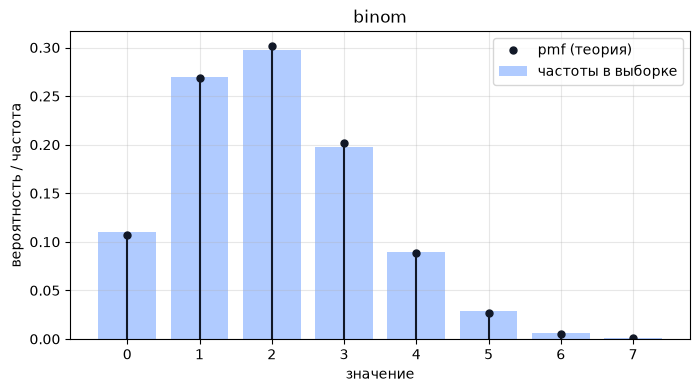

hypergeom: частота X >= 3 = 0.2978, вероятность = 0.2910


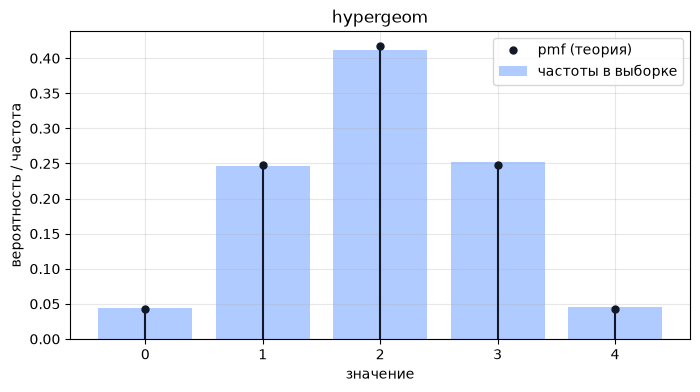

In [176]:
batch_samples = {}
for name, law in batch_laws.items():
    batch_samples[name] = law.rvs(size=10000, random_state=4)

for name, law in batch_laws.items():
    s = batch_samples[name]
    print(f"{name}: частота X >= 3 = {(sum(x >= 3 for x in s)/len(s)):.4f}, вероятность = {law.sf(2):.4f}")
    plot_dist(s, law, title=name)

**Вопросы.**
1. Почему ожидания совпали, а дисперсии разные? Что делает выборка без возвращения с разбросом?
2. Чем отличаются частота в выборке и вероятность? Почему они близки?

**Ответ:** 
1. Дисперсии разные, так как считаются по разному для биномиального формула `Var(X) = n*p*q` а для гипергеометрического формула `Var(X) = N*p*q*(M - N/M - 1)`. Выборка без возвращения с разбросом - уменьшает дисперсию это видно по формуле самого гипергеометрического распредления.
2. Выборка это теоритическая часть, а частота практическая. Соответственно, если увеличивать кол-во испытаний, то частота будет приближаться к выборке, поэтому они близки